# Neural Graphics Ex1: Training Your Own Diffusion Model!

## Setup environment

In [ ]:
# We recommend using these utils.
# https://google.github.io/mediapy/mediapy.html
# https://einops.rocks/
!pip install mediapy einops --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 35.2 MB/s eta 0:00:00


In [ ]:
# Import essential modules. Feel free to add whatever you need.
import torch
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from tqdm import tqdm

# My imports
from torchvision.utils import make_grid
from torchvision import transforms

### Seed your work
To be able to reproduce your code, please use a random seed from this point onward.

In [ ]:
def seed_everything(seed):
  torch.cuda.manual_seed(seed)
  torch.manual_seed(seed)

YOUR_SEED = 180 # modify if you want
seed_everything(YOUR_SEED)

## 1. Basic Ops and UNet blocks
**Notations:**  
 * `Conv2D(kernel_size, stride, padding)` is `nn.Conv2d()`  
 * `BN` is `nn.BatchNorm2d()`  
 * `GELU` is `nn.GELU()`  
 * `ConvTranspose2D(kernel_size, stride, padding)` is `nn.ConvTranspose2d()`  
 * `AvgPool(kernel_size)` is `nn.AvgPool2d()`  
 * `Linear` is `nn.Linear()`  
 * `N`, `C`, `W` and `H` are batch size, channels num, weight and height respectively


### Basic Ops

In [ ]:
class Conv(nn.Module):
    """
    A convolutional layer that doesn’t change the image
    resolution, only the channel dimension
    Applies nn.Conv2d(3, 1, 1) followed by BN and GELU.
    """
    def __init__(self, in_channels: int, out_channels: int):
        """
        Initializes the Conv layer
        Args:
            in_channels (int): The number of input channels
            out_channels (int): The number of output channels
        """
        super().__init__()
        self.conv2d = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.BN = nn.BatchNorm2d(out_channels)
        self.GELU = nn.GELU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels, H, W) input tensor.

        Returns:
            (N, out_channels, H, W) output tensor.
        """
        return self.GELU(self.BN(self.conv2d(x)))

class DownConv(nn.Module):
    """
        A convolutional layer downsamples the tensor by 2.
        The layer consists of Conv2D(3, 2, 1) followed by BN and GELU.
    """
    def __init__(self, in_channels: int, out_channels: int):
        """
        Initializes the DownConv layer
        Args:
            in_channels (int): The number of input channels
            out_channels (int): The number of output channels
        """
        super().__init__()
        self.conv2d = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1)
        self.BN = nn.BatchNorm2d(out_channels)
        self.GELU = nn.GELU()


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels, H, W) input tensor.

        Returns:
            (N, out_channels, H/2, W/2) output tensor.
        """
        return self.GELU(self.BN(self.conv2d(x)))


class UpConv(nn.Module):
    """
    A convolutional layer that upsamples the tensor by 2.
    The layer consists of ConvTranspose2d(4, 2, 1) followed by
    BN and GELU.
    """
    def __init__(self, in_channels: int, out_channels: int):
        """
        Initializes the UpConv layer
        Args:
            in_channels (int): The number of input channels
            out_channels (int): The number of output channels
        """
        super().__init__()
        self.convTranspose2d = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1)
        self.BN = nn.BatchNorm2d(out_channels)
        self.GELU = nn.GELU()


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels, H, W) input tensor.

        Returns:
            (N, out_channels, H*2, W*2) output tensor.
        """
        return self.GELU(self.BN(self.convTranspose2d(x)))


class Flatten(nn.Module):
    """
    Average pooling layer that flattens a 7x7 tensor into a 1x1 tensor.
    The layer consists of AvgPool followed by GELU.
    """
    def __init__(self):
        super().__init__()
        self.avg_pool = nn.AvgPool2d(kernel_size=7)
        self.GELU = nn.GELU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, 7, 7) input tensor.

        Returns:
            (N, C, 1, 1) output tensor.
        """
        return self.GELU(self.avg_pool(x))


class Unflatten(nn.Module):
    """
      Convolutional layer that unflattens/upsamples a 1x1 tensor into a
      7x7 tensor. The layer consists of ConvTranspose2D(7, 7, 0)
      followed by BN and GELU.
    """
    def __init__(self, in_channels: int):
        """
        Initializes Unflatten layer
        Args:
            in_channels (int): The number of input channels
        """
        super().__init__()
        self.convTranspose2d = nn.ConvTranspose2d(in_channels, in_channels, kernel_size=7, stride=7, padding=0)
        self.BN = nn.BatchNorm2d(in_channels)
        self.GELU = nn.GELU()
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels, 1, 1) input tensor.

        Returns:
            (N, in_channels, 7, 7) output tensor.
        """
        return self.GELU(self.BN(self.convTranspose2d(x)))

class FC(nn.Module):
    """
    Fully connected layer, consisting of nn.linear followed by GELU.
    """
    def __init__(self, in_channels: int, out_channels: int):
        """
        Initializes the FC layer
        Args:
            in_channels (int): The number of input channels
            out_channels (int): The number of output channels
        """
        super().__init__()
        self.lin = nn.Linear(in_channels, out_channels)
        self.GELU = nn.GELU()
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels) input tensor.

        Returns:
            (N, out_channels) output tensor.
        """
        return self.GELU(self.lin(x))



### UNet Blocks

In [ ]:
class ConvBlock(nn.Module):
    """
    Two consecutive Conv operations.
    Note that it has the same input and output shape as Conv.
    """
    def __init__(self, in_channels: int, out_channels: int):
        """
        Initializes ConvBlock
        Args:
            in_channels (int): The number of input channels
            out_channels (int): The number of output channels
        """
        super().__init__()
        self.conv = Conv(in_channels, out_channels)
        self.conv2 = Conv(out_channels, out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels, H, W) input tensor.

        Returns:
            (N, out_channels, H, W) output tensor.
        """
        return self.conv2(self.conv(x))


class DownBlock(nn.Module):
    """
    DownConv followed by ConvBlock. Note that it has the same input and output
    shape as DownConv.
    """
    def __init__(self, in_channels: int, out_channels: int):
        """
        Initializes DownBlock
        Args:
            in_channels (int): The number of input channels
            out_channels (int): The number of output channels
        """
        super().__init__()
        self.downConv = DownConv(in_channels, out_channels)
        self.convBlock = ConvBlock(out_channels, out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels, H, W) input tensor.

        Returns:
            (N, out_channels, H/2, W/2) output tensor.
        """
        return self.convBlock(self.downConv(x))


class UpBlock(nn.Module):
    """
    UpConv followed by ConvBlock.
    Note that it has the same input and output shape as UpConv
    """
    def __init__(self, in_channels: int, out_channels: int):
        """
        Initializes UpBlock
        Args:
            in_channels (int): The number of input channels
            out_channels (int): The number of output channels
        """
        super().__init__()
        self.upConv = UpConv(in_channels, out_channels)
        self.convBlock = ConvBlock(out_channels, out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels, H, W) input tensor.

        Returns:
            (N, out_channels, H*2, W*2) output tensor.
        """
        return self.convBlock(self.upConv(x))

class FCBlock(nn.Module):
    """
    Fully-connected Block, consisting of FC layer followed by Linear layer. Note
    that it has the same input and output shape as FC.
    """
    def __init__(self, in_channels: int, out_channels: int):
        """
        Initializes FCBlock
        Args:
            in_channels (int): The number of input channels
            out_channels (int): The number of output channels
        """
        super().__init__()
        self.fc = FC(in_channels, out_channels)
        self.lin = nn.Linear(out_channels, out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, in_channels) input tensor.

        Returns:
            (N, out_channels) output tensor.
        """
        return self.lin(self.fc(x))

## 2. Unconditional Diffusion Framework


### 2.1 UNet architecture

In [ ]:
class DenoisingUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int
    ):
        super().__init__()
        # Time embeddings
        self.first_t_injection = FCBlock(1, 2 * num_hiddens)
        self.second_t_injection = FCBlock(1, num_hiddens)

        # Encoder
        self.first_convBlock = ConvBlock(in_channels, num_hiddens)
        self.downBlock1 = DownBlock(num_hiddens, num_hiddens)
        self.downBlock2 = DownBlock(num_hiddens, 2 * num_hiddens)

        # BottleNeck
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * num_hiddens)

        # Decoder
        self.upBlock1 = UpBlock(4 * num_hiddens, num_hiddens)
        self.upBlock2 = UpBlock(2 * num_hiddens, num_hiddens)

        # Last layers
        self.end_convBlock = ConvBlock(2 * num_hiddens, num_hiddens)
        self.last_conv = nn.Conv2d(num_hiddens, in_channels, kernel_size=1, padding=0)



    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N, 1) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # time embeddings ------------------------------------------------------
        t_first  = self.first_t_injection(t)                         # (N, 2D)
        t_second = self.second_t_injection(t)                        # (N, D)

        # encoder --------------------------------------------------------------
        level_1 = self.first_convBlock(x)                            # (N, D ,28,28)
        level_2 = self.downBlock1(level_1)                           # (N, D ,14,14)
        level_3 = self.downBlock2(level_2)                           # (N, 2D, 7,7)

        # bottleneck -----------------------------------------------------------
        flat    = self.flatten(level_3).squeeze(-1).squeeze(-1)      # (N, 2D)
        unflat  = self.unflatten(flat.unsqueeze(-1).unsqueeze(-1))   # (N, 2D,7,7)
        unflat = unflat + t_first.unsqueeze(-1).unsqueeze(-1)        # (N, 2D,7,7)

        # decoder --------------------------------------------------------------
        x = self.upBlock1(torch.cat([level_3, unflat], dim=1))       # (N, D,14,14)
        x = x + t_second.unsqueeze(-1).unsqueeze(-1)                 # (N, D,14,14)
        x = self.upBlock2(torch.cat([level_2, x], dim=1))            # (N, D,28,28)

        # last layers --------------------------------------------------------------
        x = self.end_convBlock(torch.cat([level_1, x], dim=1))       # (N, D,28,28)

        return self.last_conv(x)                                     # (N, C,28,28)




### 2.1 DDPM Forward and Inverse Process


In [ ]:
def ddpm_schedule(beta1: float, beta2: float, num_ts: int, device: str = 'cuda') -> dict:
    """Constants for DDPM training and sampling.

    Arguments:
        beta1: float, starting beta value.
        beta2: float, ending beta value.
        num_ts: int, number of timesteps.

    Returns:
        dict with keys:
            betas: linear schedule of betas from beta1 to beta2.
            alphas: 1 - betas.
            alpha_bars: cumulative product of alphas.
    """
    assert beta1 < beta2 < 1.0, "Expect beta1 < beta2 < 1.0."
    # Create a list β of length T, such that β0 = 0.0001 and βT = 0.02 and all other elements βt for t ∈ {1, · · · , T − 1} are evenly spaced between the two.
    betas = torch.linspace(beta1, beta2, num_ts + 1, device=device)
    # α_t = 1 − β_t
    alphas = 1 - betas
    # α ̄ =Qt α is a comulative product of α for s∈{1,···,t}
    alpha_bars = torch.cumprod(alphas, dim=0)
    return {
        "betas": betas,
        "alphas": alphas,
        "alpha_bars": alpha_bars,
    }


In [ ]:
def ddpm_forward(
    unet: DenoisingUNet,
    ddpm_schedule: dict,
    x_0: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1 of the DDPM paper (not including gradient step).

    Args:
        unet: DenoisingUNet
        ddpm_schedule: dict
        x_0: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) diffusion loss.
    """
    unet.train()
    device = x_0.device
    N = x_0.size(0)


    # t ∼ Uniform({1,...,T})
    t = torch.randint(1, num_ts + 1, (N,), device=device, dtype=torch.long)
    t_norm = t.float().unsqueeze(1) / num_ts        # (N,1)
    alpha_bar_t = ddpm_schedule["alpha_bars"].gather(0, t).view(N, 1, 1, 1)


    # ε ∼ N(0,I)
    eps = torch.randn_like(x_0)                             # (N,C,H,W)

    # x_t = √α ̄_t * x_0 + √ 1 − α ̄_t * ε
    x_t = torch.sqrt(alpha_bar_t) * x_0 + torch.sqrt(1 - alpha_bar_t) * eps

    # εˆ = ε_θ(x_t , t)
    eps_pred = unet(x_t, t_norm)

    return torch.nn.functional.mse_loss(eps, eps_pred)


In [ ]:
@torch.inference_mode()
def ddpm_sample(
    unet: DenoisingUNet,
    ddpm_schedule: dict,
    img_wh: tuple[int, int],
    batch_size: int,
    num_ts: int
) -> torch.Tensor:
    """Algorithm 2 of the DDPM paper.

    Args:
        unet: DenoisingUNet
        ddpm_schedule: dict
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    device = next(unet.parameters()).device
    x_t = torch.randn((batch_size, 1, *img_wh), device=device)

    # for t from T to 1, stepsize−1
    for t_curr in tqdm(range(num_ts, 0, -1), desc="Sampling"):
        t = torch.full((batch_size,), t_curr, device=device, dtype=torch.long)
        t_norm = t.float().unsqueeze(1) / num_ts

        alpha_bar_t = ddpm_schedule["alpha_bars"].gather(0, t).view(batch_size, 1, 1, 1)
        alpha_bar_t_prev = ddpm_schedule["alpha_bars"].gather(0, t-1).view(batch_size, 1, 1, 1)
        alpha_t = ddpm_schedule["alphas"].gather(0, t).view(batch_size, 1, 1, 1)
        beta_t = ddpm_schedule["betas"].gather(0, t).view(batch_size, 1, 1, 1)

        if t_curr > 1:
          # z ∼ N(0,I)
          z = torch.randn_like(x_t)
        else:
          # z = 0
          z = torch.zeros_like(x_t)

        # εˆ = ε_θ(x_t , t)
        eps_pred = unet(x_t, t_norm)

        # xˆ0 = 1/√α ̄_t * x_t − sqrt(1−α ̄_t)*εˆ
        x_0_pred = (1 / torch.sqrt(alpha_bar_t)) * (x_t - torch.sqrt(1 - alpha_bar_t)  * eps_pred)

        # x_t−1 = sqrt(α_t−1) β_t xˆ0/ (1-α_t) + sqrt(α_t)(1−α_t−1)x_t/(1-α_t) + βtz
        x_0_pred_section = torch.sqrt(alpha_bar_t_prev) * beta_t * x_0_pred/(1-alpha_bar_t)
        x_t_section = torch.sqrt(alpha_t)*(1- alpha_bar_t_prev)*x_t/(1-alpha_bar_t)
        z_section = torch.sqrt(beta_t) * z
        x_t_prev = x_0_pred_section + x_t_section + z_section
        x_t = x_t_prev
    return x_t

In [ ]:
# Do Not Modify
class DDPM(nn.Module):
    def __init__(
        self,
        unet: DenoisingUNet,
        betas: tuple[float, float] = (1e-4, 0.02),
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self._betas = betas # Changed to _betas for register_buffer of the real betas
        self.num_ts = num_ts
        self.p_uncond = p_uncond
        self.ddpm_schedule = ddpm_schedule(betas[0], betas[1], num_ts)

        for k, v in ddpm_schedule(betas[0], betas[1], num_ts).items():
            self.register_buffer(k, v, persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) diffusion loss.
        """
        return ddpm_forward(
            self.unet, self.ddpm_schedule, x, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        batch_size: int
    ):
        return ddpm_sample(
            self.unet, self.ddpm_schedule, img_wh, batch_size, self.num_ts
        )

### 2.3 Train your denoiser

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch [1/20], Step [0/938], Loss: 1.1047
Epoch [1/20], Step [100/938], Loss: 0.0686
Epoch [1/20], Step [200/938], Loss: 0.0545
Epoch [1/20], Step [300/938], Loss: 0.0455
Epoch [1/20], Step [400/938], Loss: 0.0520
Epoch [1/20], Step [500/938], Loss: 0.0519
Epoch [1/20], Step [600/938], Loss: 0.0521
Epoch [1/20], Step [700/938], Loss: 0.0527
Epoch [1/20], Step [800/938], Loss: 0.0445
Epoch [1/20], Step [900/938], Loss: 0.0442
Epoch [1/20] - Average Loss: 0.0632



Sampling: 100%|██████████| 300/300 [00:04<00:00, 63.90it/s]


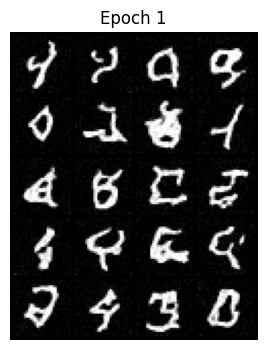

  5%|▌         | 1/20 [01:38<31:06, 98.24s/it]

Epoch [2/20], Step [0/938], Loss: 0.0474
Epoch [2/20], Step [100/938], Loss: 0.0370
Epoch [2/20], Step [200/938], Loss: 0.0365
Epoch [2/20], Step [300/938], Loss: 0.0317
Epoch [2/20], Step [400/938], Loss: 0.0418
Epoch [2/20], Step [500/938], Loss: 0.0342
Epoch [2/20], Step [600/938], Loss: 0.0354
Epoch [2/20], Step [700/938], Loss: 0.0303
Epoch [2/20], Step [800/938], Loss: 0.0296
Epoch [2/20], Step [900/938], Loss: 0.0321


 10%|█         | 2/20 [03:11<28:34, 95.26s/it]

Epoch [2/20] - Average Loss: 0.0379
Epoch [3/20], Step [0/938], Loss: 0.0356
Epoch [3/20], Step [100/938], Loss: 0.0424
Epoch [3/20], Step [200/938], Loss: 0.0444
Epoch [3/20], Step [300/938], Loss: 0.0308
Epoch [3/20], Step [400/938], Loss: 0.0302
Epoch [3/20], Step [500/938], Loss: 0.0315
Epoch [3/20], Step [600/938], Loss: 0.0281
Epoch [3/20], Step [700/938], Loss: 0.0306
Epoch [3/20], Step [800/938], Loss: 0.0311
Epoch [3/20], Step [900/938], Loss: 0.0378


 15%|█▌        | 3/20 [04:44<26:42, 94.28s/it]

Epoch [3/20] - Average Loss: 0.0340
Epoch [4/20], Step [0/938], Loss: 0.0357
Epoch [4/20], Step [100/938], Loss: 0.0295
Epoch [4/20], Step [200/938], Loss: 0.0320
Epoch [4/20], Step [300/938], Loss: 0.0301
Epoch [4/20], Step [400/938], Loss: 0.0311
Epoch [4/20], Step [500/938], Loss: 0.0360
Epoch [4/20], Step [600/938], Loss: 0.0280
Epoch [4/20], Step [700/938], Loss: 0.0310
Epoch [4/20], Step [800/938], Loss: 0.0326
Epoch [4/20], Step [900/938], Loss: 0.0297


 20%|██        | 4/20 [06:17<25:02, 93.89s/it]

Epoch [4/20] - Average Loss: 0.0316
Epoch [5/20], Step [0/938], Loss: 0.0236
Epoch [5/20], Step [100/938], Loss: 0.0315
Epoch [5/20], Step [200/938], Loss: 0.0253
Epoch [5/20], Step [300/938], Loss: 0.0293
Epoch [5/20], Step [400/938], Loss: 0.0320
Epoch [5/20], Step [500/938], Loss: 0.0299
Epoch [5/20], Step [600/938], Loss: 0.0236
Epoch [5/20], Step [700/938], Loss: 0.0295
Epoch [5/20], Step [800/938], Loss: 0.0298
Epoch [5/20], Step [900/938], Loss: 0.0392
Epoch [5/20] - Average Loss: 0.0306



Sampling: 100%|██████████| 300/300 [00:04<00:00, 63.74it/s]


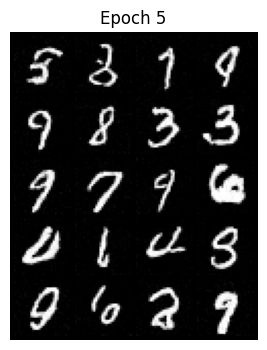

 25%|██▌       | 5/20 [07:56<23:54, 95.64s/it]

Epoch [6/20], Step [0/938], Loss: 0.0306
Epoch [6/20], Step [100/938], Loss: 0.0301
Epoch [6/20], Step [200/938], Loss: 0.0384
Epoch [6/20], Step [300/938], Loss: 0.0350
Epoch [6/20], Step [400/938], Loss: 0.0308
Epoch [6/20], Step [500/938], Loss: 0.0247
Epoch [6/20], Step [600/938], Loss: 0.0353
Epoch [6/20], Step [700/938], Loss: 0.0224
Epoch [6/20], Step [800/938], Loss: 0.0280
Epoch [6/20], Step [900/938], Loss: 0.0244


 30%|███       | 6/20 [09:29<22:08, 94.88s/it]

Epoch [6/20] - Average Loss: 0.0296
Epoch [7/20], Step [0/938], Loss: 0.0275
Epoch [7/20], Step [100/938], Loss: 0.0250
Epoch [7/20], Step [200/938], Loss: 0.0268
Epoch [7/20], Step [300/938], Loss: 0.0310
Epoch [7/20], Step [400/938], Loss: 0.0239
Epoch [7/20], Step [500/938], Loss: 0.0253
Epoch [7/20], Step [600/938], Loss: 0.0281
Epoch [7/20], Step [700/938], Loss: 0.0344
Epoch [7/20], Step [800/938], Loss: 0.0295
Epoch [7/20], Step [900/938], Loss: 0.0325


 35%|███▌      | 7/20 [11:03<20:26, 94.33s/it]

...

 40%|████      | 8/20 [12:36<18:47, 93.96s/it]

Epoch [8/20] - Average Loss: 0.0285
Epoch [9/20], Step [0/938], Loss: 0.0333
Epoch [9/20], Step [100/938], Loss: 0.0257
Epoch [9/20], Step [200/938], Loss: 0.0228
Epoch [9/20], Step [300/938], Loss: 0.0293
Epoch [9/20], Step [400/938], Loss: 0.0273
Epoch [9/20], Step [500/938], Loss: 0.0343
Epoch [9/20], Step [600/938], Loss: 0.0223
Epoch [9/20], Step [700/938], Loss: 0.0294
Epoch [9/20], Step [800/938], Loss: 0.0206
Epoch [9/20], Step [900/938], Loss: 0.0263


 45%|████▌     | 9/20 [14:09<17:10, 93.66s/it]

Epoch [9/20] - Average Loss: 0.0278
Epoch [10/20], Step [0/938], Loss: 0.0246
Epoch [10/20], Step [100/938], Loss: 0.0251
Epoch [10/20], Step [200/938], Loss: 0.0274
Epoch [10/20], Step [300/938], Loss: 0.0268
Epoch [10/20], Step [400/938], Loss: 0.0289
Epoch [10/20], Step [500/938], Loss: 0.0276
Epoch [10/20], Step [600/938], Loss: 0.0352
Epoch [10/20], Step [700/938], Loss: 0.0336
Epoch [10/20], Step [800/938], Loss: 0.0291
Epoch [10/20], Step [900/938], Loss: 0.0233
Epoch [10/20] - Average Loss: 0.0274



Sampling: 100%|██████████| 300/300 [00:04<00:00, 63.82it/s]


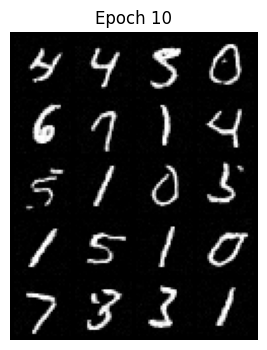

 50%|█████     | 10/20 [15:47<15:49, 94.99s/it]

Epoch [11/20], Step [0/938], Loss: 0.0281
Epoch [11/20], Step [100/938], Loss: 0.0297
Epoch [11/20], Step [200/938], Loss: 0.0304
Epoch [11/20], Step [300/938], Loss: 0.0256
Epoch [11/20], Step [400/938], Loss: 0.0218
Epoch [11/20], Step [500/938], Loss: 0.0188
Epoch [11/20], Step [600/938], Loss: 0.0284
Epoch [11/20], Step [700/938], Loss: 0.0257
Epoch [11/20], Step [800/938], Loss: 0.0272
Epoch [11/20], Step [900/938], Loss: 0.0231


 55%|█████▌    | 11/20 [17:20<14:09, 94.42s/it]

Epoch [11/20] - Average Loss: 0.0274
Epoch [12/20], Step [0/938], Loss: 0.0249
Epoch [12/20], Step [100/938], Loss: 0.0286
Epoch [12/20], Step [200/938], Loss: 0.0299
Epoch [12/20], Step [300/938], Loss: 0.0258
Epoch [12/20], Step [400/938], Loss: 0.0345
Epoch [12/20], Step [500/938], Loss: 0.0309
Epoch [12/20], Step [600/938], Loss: 0.0263
Epoch [12/20], Step [700/938], Loss: 0.0262
Epoch [12/20], Step [800/938], Loss: 0.0252
Epoch [12/20], Step [900/938], Loss: 0.0271


 60%|██████    | 12/20 [18:53<12:31, 93.98s/it]

...

 65%|██████▌   | 13/20 [20:26<10:56, 93.73s/it]

Epoch [13/20] - Average Loss: 0.0269
Epoch [14/20], Step [0/938], Loss: 0.0266
Epoch [14/20], Step [100/938], Loss: 0.0309
Epoch [14/20], Step [200/938], Loss: 0.0229
Epoch [14/20], Step [300/938], Loss: 0.0234
Epoch [14/20], Step [400/938], Loss: 0.0256
Epoch [14/20], Step [500/938], Loss: 0.0256
Epoch [14/20], Step [600/938], Loss: 0.0298
Epoch [14/20], Step [700/938], Loss: 0.0305
Epoch [14/20], Step [800/938], Loss: 0.0287
Epoch [14/20], Step [900/938], Loss: 0.0295


 70%|███████   | 14/20 [21:59<09:21, 93.54s/it]

Epoch [14/20] - Average Loss: 0.0267
Epoch [15/20], Step [0/938], Loss: 0.0264
Epoch [15/20], Step [100/938], Loss: 0.0276
Epoch [15/20], Step [200/938], Loss: 0.0252
Epoch [15/20], Step [300/938], Loss: 0.0255
Epoch [15/20], Step [400/938], Loss: 0.0312
Epoch [15/20], Step [500/938], Loss: 0.0220
Epoch [15/20], Step [600/938], Loss: 0.0250
Epoch [15/20], Step [700/938], Loss: 0.0253
Epoch [15/20], Step [800/938], Loss: 0.0267
Epoch [15/20], Step [900/938], Loss: 0.0271
Epoch [15/20] - Average Loss: 0.0264



Sampling: 100%|██████████| 300/300 [00:04<00:00, 63.67it/s]


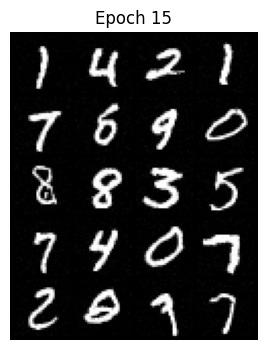

 75%|███████▌  | 15/20 [23:37<07:54, 94.87s/it]

Epoch [16/20], Step [0/938], Loss: 0.0247
Epoch [16/20], Step [100/938], Loss: 0.0282
Epoch [16/20], Step [200/938], Loss: 0.0238
Epoch [16/20], Step [300/938], Loss: 0.0342
Epoch [16/20], Step [400/938], Loss: 0.0329
Epoch [16/20], Step [500/938], Loss: 0.0326
Epoch [16/20], Step [600/938], Loss: 0.0321
Epoch [16/20], Step [700/938], Loss: 0.0247
Epoch [16/20], Step [800/938], Loss: 0.0267
Epoch [16/20], Step [900/938], Loss: 0.0266


 80%|████████  | 16/20 [25:10<06:17, 94.31s/it]

Epoch [16/20] - Average Loss: 0.0265
Epoch [17/20], Step [0/938], Loss: 0.0167
Epoch [17/20], Step [100/938], Loss: 0.0242
Epoch [17/20], Step [200/938], Loss: 0.0249
Epoch [17/20], Step [300/938], Loss: 0.0295
Epoch [17/20], Step [400/938], Loss: 0.0305
Epoch [17/20], Step [500/938], Loss: 0.0349
Epoch [17/20], Step [600/938], Loss: 0.0335
Epoch [17/20], Step [700/938], Loss: 0.0262
Epoch [17/20], Step [800/938], Loss: 0.0254
Epoch [17/20], Step [900/938], Loss: 0.0260


 85%|████████▌ | 17/20 [26:43<04:41, 93.95s/it]

...

 90%|█████████ | 18/20 [28:16<03:07, 93.66s/it]

Epoch [18/20] - Average Loss: 0.0263
Epoch [19/20], Step [0/938], Loss: 0.0248
Epoch [19/20], Step [100/938], Loss: 0.0278
Epoch [19/20], Step [200/938], Loss: 0.0200
Epoch [19/20], Step [300/938], Loss: 0.0239
Epoch [19/20], Step [400/938], Loss: 0.0241
Epoch [19/20], Step [500/938], Loss: 0.0289
Epoch [19/20], Step [600/938], Loss: 0.0245
Epoch [19/20], Step [700/938], Loss: 0.0256
Epoch [19/20], Step [800/938], Loss: 0.0316
Epoch [19/20], Step [900/938], Loss: 0.0264


 95%|█████████▌| 19/20 [29:49<01:33, 93.47s/it]

Epoch [19/20] - Average Loss: 0.0263
Epoch [20/20], Step [0/938], Loss: 0.0210
Epoch [20/20], Step [100/938], Loss: 0.0294
Epoch [20/20], Step [200/938], Loss: 0.0263
Epoch [20/20], Step [300/938], Loss: 0.0298
Epoch [20/20], Step [400/938], Loss: 0.0318
Epoch [20/20], Step [500/938], Loss: 0.0354
Epoch [20/20], Step [600/938], Loss: 0.0268
Epoch [20/20], Step [700/938], Loss: 0.0300
Epoch [20/20], Step [800/938], Loss: 0.0248
Epoch [20/20], Step [900/938], Loss: 0.0323
Epoch [20/20] - Average Loss: 0.0259



Sampling: 100%|██████████| 300/300 [00:04<00:00, 63.86it/s]


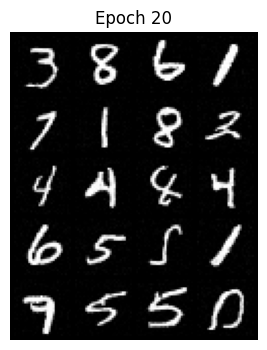

100%|██████████| 20/20 [31:27<00:00, 94.38s/it]


In [ ]:
# Hyper parameters - Modify if you wish
num_hidden = 128
batch_size = 64
num_epochs = 20
lr = 2e-4
img_wh = (28, 28)
eval_batch_size=20
T=300

# Init MNIST data loaders
train_data = MNIST(root='./data', train=True, download=True, transform=ToTensor())
test_data = MNIST(root='./data', train=False, download=True, transform=ToTensor())
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
eval_loader = DataLoader(test_data, batch_size=eval_batch_size, shuffle=True) #Not usefull now, but will be for evaluating class-conditioned denoiser (3.3)

# Init denoiser and DDPM wrapper
denosier_unet = DenoisingUNet(in_channels=1 , num_hiddens=num_hidden)
ddpm = DDPM(denosier_unet, num_ts=T)

# Optimizer and device setup - Adam optimizer with exponential learning rate decay
optimizer = torch.optim.Adam(ddpm.parameters(), lr = lr)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optimizer, gamma = 0.1**(1.0/num_epochs))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ddpm.to(device)

# My code:
batch_losses = []
epoch_losses = []

for epoch in tqdm(range(num_epochs)):
  ddpm.train()  # Set the model to training mode
  epoch_loss = 0.0
  for batch, (data, label) in enumerate(train_loader):
      optimizer.zero_grad()
      data = data.to(device)
      loss = ddpm(data)
      loss.backward()  # Compute gradients
      optimizer.step()  # Update weights
      batch_loss = loss.item()
      batch_losses += [batch_loss]
      epoch_loss += batch_loss

      if batch % 100 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Step [{batch}/{len(train_loader)}], Loss: {batch_loss:.4f}")

  avg_epoch_loss = epoch_loss / len(train_loader)
  print(f"Epoch [{epoch+1}/{num_epochs}] - Average Loss: {avg_epoch_loss:.4f}")
  scheduler.step()


  ddpm.eval() # changes the behaior of BN and Dropouts layers
  epoch_losses += [avg_epoch_loss]
  if epoch in [0, 4, 9, 14, 19]:
    with torch.no_grad():
      samples = ddpm.sample(img_wh, eval_batch_size)
    # plot samples
    grid = make_grid(samples, nrow=4, normalize=True, value_range=(0, 1))
    plt.figure(figsize=(4, 4))
    plt.axis("off")
    plt.title(f"Epoch {epoch+1}")
    plt.imshow(grid.permute(1, 2, 0).cpu())   # CHW → HWC, move to CPU
    plt.show()




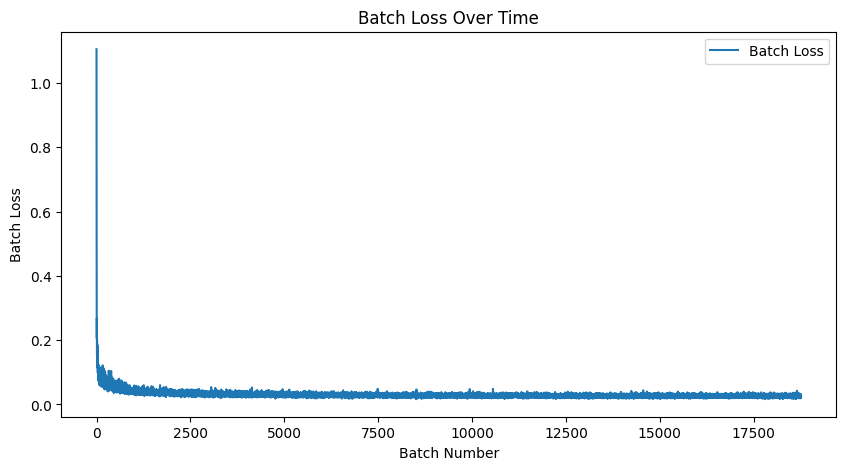

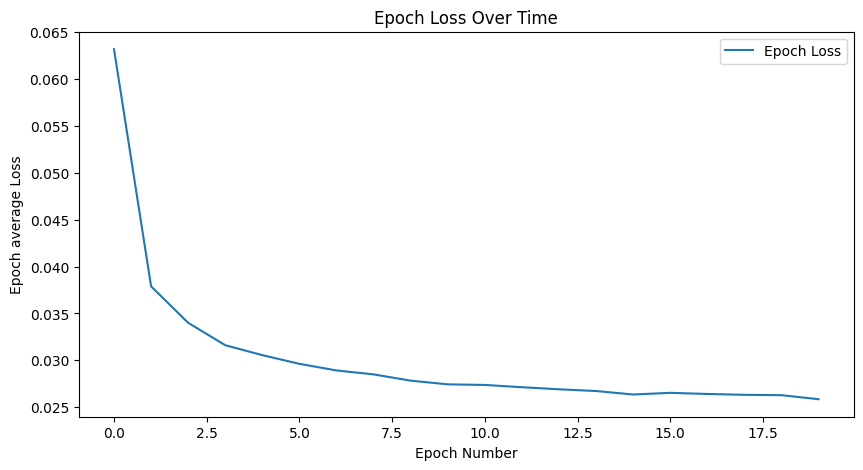

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(batch_losses, label='Batch Loss')
plt.title('Batch Loss Over Time')
plt.xlabel('Batch Number')
plt.ylabel('Batch Loss')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(epoch_losses, label='Epoch Loss')
plt.title('Epoch Loss Over Time')
plt.xlabel('Epoch Number')
plt.ylabel('Epoch average Loss')
plt.legend()
plt.show()

## 3. Implementing class-conditioned diffusion framework with CFG


###3.1 Adding Class-Conditioning to UNet architecture

In [ ]:
class ConditionalDenoisingUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # Time embeddings
        self.first_t_injection = FCBlock(1, 2 * num_hiddens)
        self.second_t_injection = FCBlock(1, num_hiddens)

        # Class embeddings
        self.first_class_injection = FCBlock(10, 2 * num_hiddens)
        self.second_class_injection = FCBlock(10, num_hiddens)

        # Encoder
        self.first_convBlock = ConvBlock(in_channels, num_hiddens)
        self.downBlock1 = DownBlock(num_hiddens, num_hiddens)
        self.downBlock2 = DownBlock(num_hiddens, 2 * num_hiddens)

        # BottleNeck
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * num_hiddens)

        # Decoder
        self.upBlock1 = UpBlock(4 * num_hiddens, num_hiddens)
        self.upBlock2 = UpBlock(2 * num_hiddens, num_hiddens)

        # Last layers
        self.end_convBlock = ConvBlock(2 * num_hiddens, num_hiddens)
        self.last_conv = nn.Conv2d(num_hiddens, in_channels, kernel_size=1)

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N, num_classes) float condition tensor.
            t: (N, 1) normalized time tensor.
            mask: (N, 1) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # time embeddings ------------------------------------------------------
        t_first  = self.first_t_injection(t)                         # (N, 2D)
        t_second = self.second_t_injection(t)                        # (N, D)

        # class embeddings ------------------------------------------------------
        if mask is not None:
            c = c * mask.unsqueeze(1)
        c_first  = self.first_class_injection(c)                     # (N, 2D)
        c_second = self.second_class_injection(c)                    # (N, D)

        # encoder --------------------------------------------------------------
        level_1 = self.first_convBlock(x)                            # (N, D ,28,28)
        level_2 = self.downBlock1(level_1)                           # (N, D ,14,14)
        level_3 = self.downBlock2(level_2)                           # (N, 2D, 7,7)

        # bottleneck -----------------------------------------------------------
        flat    = self.flatten(level_3).squeeze(-1).squeeze(-1)      # (N, 2D)
        unflat  = self.unflatten(flat.unsqueeze(-1).unsqueeze(-1))   # (N, 2D,7,7)
        unflat = c_first.unsqueeze(-1).unsqueeze(-1) * unflat + t_first.unsqueeze(-1).unsqueeze(-1)  # (N, 2D,7,7)


        # decoder --------------------------------------------------------------
        x = self.upBlock1(torch.cat([level_3, unflat], dim=1))       # (N, D,14,14)
        x = x + t_second.unsqueeze(-1).unsqueeze(-1)                 # (N, D,14,14)
        x = c_second.unsqueeze(-1).unsqueeze(-1) * x + t_second.unsqueeze(-1).unsqueeze(-1)  # (N, D,14,14)
        x = self.upBlock2(torch.cat([level_2, x], dim=1))            # (N, D,28,28)

        # last layers------------------------------------------------------------
        x = self.end_convBlock(torch.cat([level_1, x], dim=1))       # (N, D,28,28)

        return self.last_conv(x)                                     # (N, C,28,28)

###3.2 DDPM Forward and Inverse Process with CFG

In [ ]:
def ddpm_forward(
    unet: ConditionalDenoisingUNet,
    ddpm_schedule: dict,
    x_0: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3 (not including gradient step).

    Args:
        unet: ConditionalDenoisingUNet
        ddpm_schedule: dict
        x_0: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) diffusion loss.
    """
    unet.train()
    device = x_0.device
    N = x_0.size(0)

    # Make c into a one-hot vector c
    c = torch.nn.functional.one_hot(c, num_classes=10).float()

    # Set ⃗c to ⃗0 with probability p_uncond
    mask = torch.rand(N, device = device) >= p_uncond

    # t ∼ Uniform({1,...,T})
    t = torch.randint(1, num_ts + 1, (N,), device=device, dtype=torch.long)
    t_norm = t.float().unsqueeze(1) / num_ts

    # ε ∼ N(0,I)
    eps = torch.randn_like(x_0)

    alpha_bar_t = ddpm_schedule['alpha_bars'].gather(0, t).view(N, 1, 1, 1)
    # xt=√α ̄tx0+√1−α ̄tε
    x_t = torch.sqrt(alpha_bar_t) * x_0 + torch.sqrt(1 - alpha_bar_t) * eps

    # εˆ=εθ(xt,t,⃗c)
    eps_pred = unet(x_t, c, t_norm, mask)

    return torch.nn.functional.mse_loss(eps, eps_pred)

In [ ]:
@torch.inference_mode()
def ddpm_cfg_sample(
    unet: ConditionalDenoisingUNet,
    ddpm_schedule: dict,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0
) -> torch.Tensor:
    """Algorithm 4.

    Args:
        unet: ConditionalDenoisingUNet
        ddpm_schedule: dict
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    device = next(unet.parameters()).device
    N = c.size(0)

    # Make c into a one-hot vector c
    c = torch.nn.functional.one_hot(c, num_classes=10).float()
    zeros = torch.zeros_like(c)

    # xT∼N(0,I)
    x_t = torch.randn((N, 1, *img_wh), device=c.device)

    # for t fromT to 1, stepsize−1 do
    for t_curr in tqdm(range(num_ts, 0, -1), desc="Sampling"):
        t = torch.full((N,), t_curr, device=device, dtype=torch.long)
        t_norm = t.float().unsqueeze(1) / num_ts

        if t_curr > 1:
          z = torch.randn_like(x_t)
        else:
          z = torch.zeros_like(x_t)

        alpha_bar_t = ddpm_schedule["alpha_bars"].gather(0, t).view(N, 1, 1, 1)
        alpha_bar_t_prev = ddpm_schedule["alpha_bars"].gather(0, t-1).view(N, 1, 1, 1)
        alpha_t = ddpm_schedule["alphas"].gather(0, t).view(N, 1, 1, 1)
        beta_t = ddpm_schedule["betas"].gather(0, t).view(N, 1, 1, 1)

        # ε_cond = ε_θ(x_t, t ,c)
        eps_cond = unet(x_t, c, t_norm)

        # ε_uncond = ε_θ(x_t,t, 0)
        eps_uncond = unet(x_t, zeros, t_norm)

        # εˆ = ε_uncond + γ(ε_cond − ε_uncond)
        eps_pred = eps_uncond + guidance_scale * (eps_cond - eps_uncond)

        # xˆ0=1/√α ̄t (x_t − sqrt(1−α ̄t)εˆ
        x_0_pred = (1 / torch.sqrt(alpha_bar_t)) * (x_t - torch.sqrt(1 - alpha_bar_t)  * eps_pred)

        # x_t−1 = sqrt(α_t−1) β_t xˆ0/ (1-α_t) + sqrt(α_t)(1−α_t−1)x_t/(1-α_t)+ βtz
        x_0_pred_section = torch.sqrt(alpha_bar_t_prev) * beta_t * x_0_pred/(1-alpha_bar_t)
        x_t_section = torch.sqrt(alpha_t)*(1 - alpha_bar_t_prev) * x_t / (1-alpha_bar_t)
        z_section = torch.sqrt(beta_t) * z
        x_t_prev = x_0_pred_section + x_t_section + z_section
        x_t = x_t_prev
    return x_t



In [ ]:
# Do Not Modify
class DDPM(nn.Module):
    def __init__(
        self,
        unet: ConditionalDenoisingUNet,
        betas: tuple[float, float] = (1e-4, 0.02),
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.betas = betas
        self.num_ts = num_ts
        self.p_uncond = p_uncond
        self.ddpm_schedule = ddpm_schedule(betas[0], betas[1], num_ts)

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) diffusion loss.
        """
        return ddpm_forward(
            self.unet, self.ddpm_schedule, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0
    ):
        return ddpm_cfg_sample(
            self.unet, self.ddpm_schedule, c, img_wh, self.num_ts, guidance_scale
        )

###3.3 Train your class-conditioned denoiser

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch [1/20], Step [0/938], Loss: 1.0845
Epoch [1/20], Step [100/938], Loss: 0.0769
Epoch [1/20], Step [200/938], Loss: 0.0631
Epoch [1/20], Step [300/938], Loss: 0.0553
Epoch [1/20], Step [400/938], Loss: 0.0460
Epoch [1/20], Step [500/938], Loss: 0.0524
Epoch [1/20], Step [600/938], Loss: 0.0461
Epoch [1/20], Step [700/938], Loss: 0.0793
Epoch [1/20], Step [800/938], Loss: 0.0474
Epoch [1/20], Step [900/938], Loss: 0.0595
Epoch [1/20] - Average Loss: 0.0608



Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.37it/s]


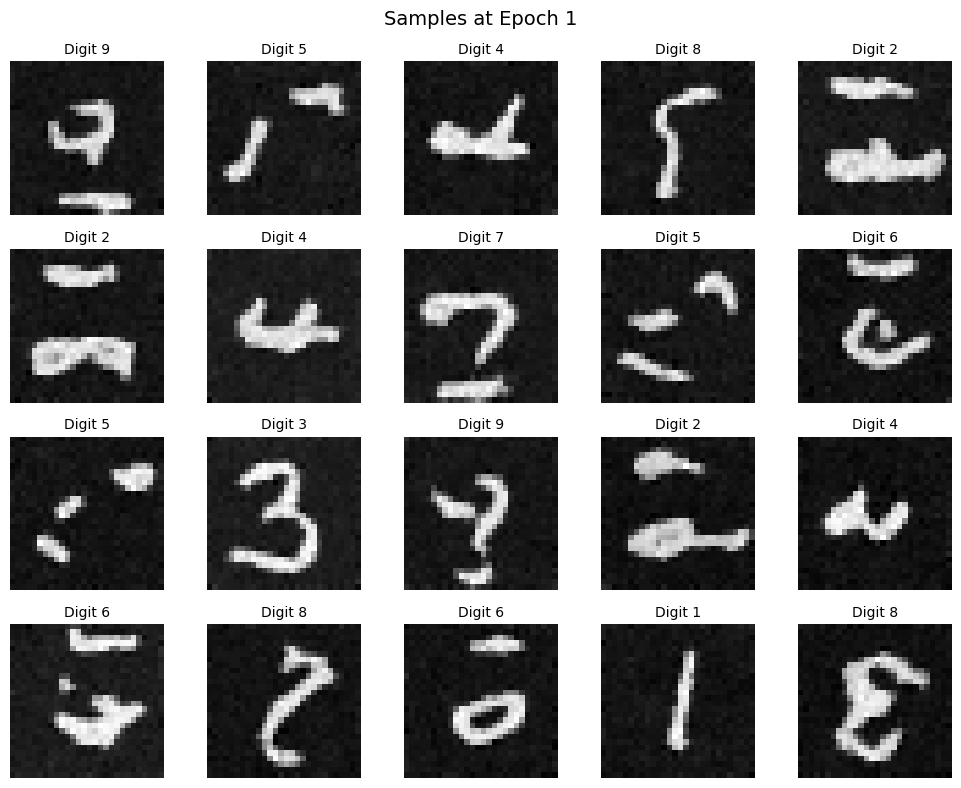

  5%|▌         | 1/20 [01:45<33:22, 105.41s/it]

Epoch [2/20], Step [0/938], Loss: 0.0458
Epoch [2/20], Step [100/938], Loss: 0.0378
Epoch [2/20], Step [200/938], Loss: 0.0352
Epoch [2/20], Step [300/938], Loss: 0.0398
Epoch [2/20], Step [400/938], Loss: 0.0343
Epoch [2/20], Step [500/938], Loss: 0.0337
Epoch [2/20], Step [600/938], Loss: 0.0346
Epoch [2/20], Step [700/938], Loss: 0.0421
Epoch [2/20], Step [800/938], Loss: 0.0318
Epoch [2/20], Step [900/938], Loss: 0.0312


 10%|█         | 2/20 [03:20<29:46, 99.24s/it] 

Epoch [2/20] - Average Loss: 0.0377
Epoch [3/20], Step [0/938], Loss: 0.0332
Epoch [3/20], Step [100/938], Loss: 0.0285
Epoch [3/20], Step [200/938], Loss: 0.0226
Epoch [3/20], Step [300/938], Loss: 0.0354
Epoch [3/20], Step [400/938], Loss: 0.0248
Epoch [3/20], Step [500/938], Loss: 0.0327
Epoch [3/20], Step [600/938], Loss: 0.0419
Epoch [3/20], Step [700/938], Loss: 0.0317
Epoch [3/20], Step [800/938], Loss: 0.0306
Epoch [3/20], Step [900/938], Loss: 0.0278


 15%|█▌        | 3/20 [04:55<27:34, 97.30s/it]

Epoch [3/20] - Average Loss: 0.0332
Epoch [4/20], Step [0/938], Loss: 0.0270
Epoch [4/20], Step [100/938], Loss: 0.0329
Epoch [4/20], Step [200/938], Loss: 0.0241
Epoch [4/20], Step [300/938], Loss: 0.0332
Epoch [4/20], Step [400/938], Loss: 0.0275
Epoch [4/20], Step [500/938], Loss: 0.0252
Epoch [4/20], Step [600/938], Loss: 0.0353
Epoch [4/20], Step [700/938], Loss: 0.0347
Epoch [4/20], Step [800/938], Loss: 0.0247
Epoch [4/20], Step [900/938], Loss: 0.0253


 20%|██        | 4/20 [06:30<25:42, 96.38s/it]

Epoch [4/20] - Average Loss: 0.0308
Epoch [5/20], Step [0/938], Loss: 0.0252
Epoch [5/20], Step [100/938], Loss: 0.0293
Epoch [5/20], Step [200/938], Loss: 0.0230
Epoch [5/20], Step [300/938], Loss: 0.0240
Epoch [5/20], Step [400/938], Loss: 0.0320
Epoch [5/20], Step [500/938], Loss: 0.0317
Epoch [5/20], Step [600/938], Loss: 0.0290
Epoch [5/20], Step [700/938], Loss: 0.0332
Epoch [5/20], Step [800/938], Loss: 0.0317
Epoch [5/20], Step [900/938], Loss: 0.0319
Epoch [5/20] - Average Loss: 0.0295



Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.31it/s]


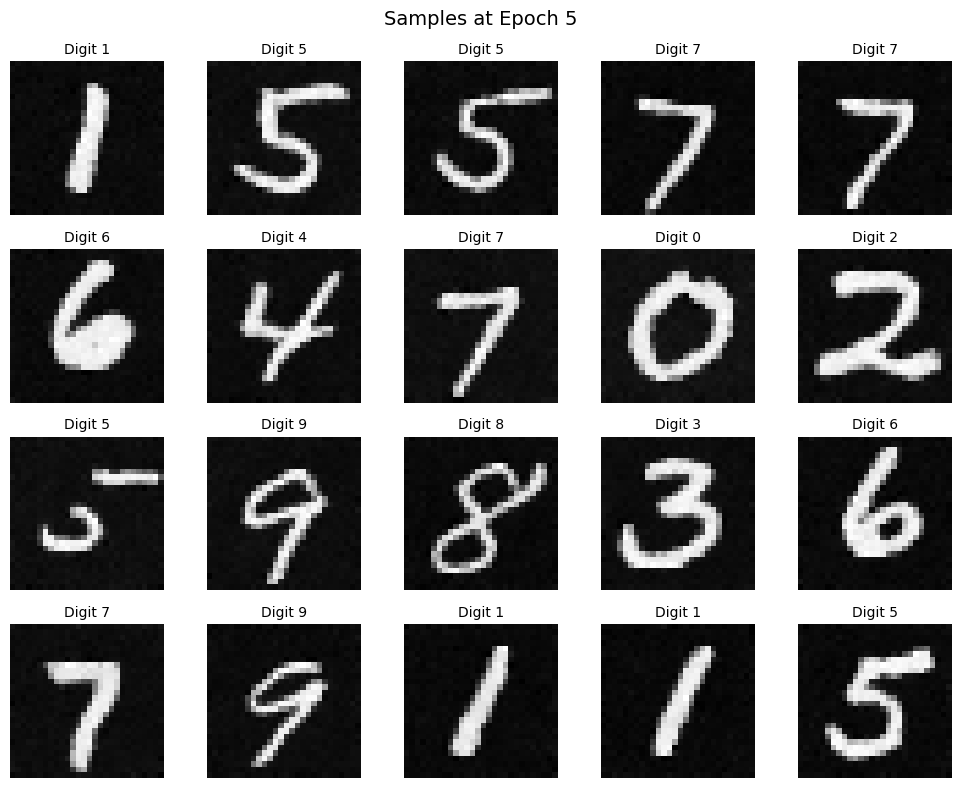

 25%|██▌       | 5/20 [08:16<24:57, 99.81s/it]

Epoch [6/20], Step [0/938], Loss: 0.0288
Epoch [6/20], Step [100/938], Loss: 0.0311
Epoch [6/20], Step [200/938], Loss: 0.0281
Epoch [6/20], Step [300/938], Loss: 0.0269
Epoch [6/20], Step [400/938], Loss: 0.0254
Epoch [6/20], Step [500/938], Loss: 0.0246
Epoch [6/20], Step [600/938], Loss: 0.0289
Epoch [6/20], Step [700/938], Loss: 0.0246
Epoch [6/20], Step [800/938], Loss: 0.0223
Epoch [6/20], Step [900/938], Loss: 0.0299


 30%|███       | 6/20 [09:51<22:54, 98.18s/it]

Epoch [6/20] - Average Loss: 0.0289
Epoch [7/20], Step [0/938], Loss: 0.0242
Epoch [7/20], Step [100/938], Loss: 0.0252
Epoch [7/20], Step [200/938], Loss: 0.0403
Epoch [7/20], Step [300/938], Loss: 0.0314
Epoch [7/20], Step [400/938], Loss: 0.0242
Epoch [7/20], Step [500/938], Loss: 0.0278
Epoch [7/20], Step [600/938], Loss: 0.0415
Epoch [7/20], Step [700/938], Loss: 0.0233
Epoch [7/20], Step [800/938], Loss: 0.0299
Epoch [7/20], Step [900/938], Loss: 0.0332


 35%|███▌      | 7/20 [11:26<21:03, 97.16s/it]

...

 40%|████      | 8/20 [13:01<19:17, 96.46s/it]

Epoch [8/20] - Average Loss: 0.0275
Epoch [9/20], Step [0/938], Loss: 0.0288
Epoch [9/20], Step [100/938], Loss: 0.0273
Epoch [9/20], Step [200/938], Loss: 0.0287
Epoch [9/20], Step [300/938], Loss: 0.0262
Epoch [9/20], Step [400/938], Loss: 0.0298
Epoch [9/20], Step [500/938], Loss: 0.0284
Epoch [9/20], Step [600/938], Loss: 0.0224
Epoch [9/20], Step [700/938], Loss: 0.0333
Epoch [9/20], Step [800/938], Loss: 0.0348
Epoch [9/20], Step [900/938], Loss: 0.0231


 45%|████▌     | 9/20 [14:36<17:36, 96.01s/it]

Epoch [9/20] - Average Loss: 0.0272
Epoch [10/20], Step [0/938], Loss: 0.0298
Epoch [10/20], Step [100/938], Loss: 0.0278
Epoch [10/20], Step [200/938], Loss: 0.0259
Epoch [10/20], Step [300/938], Loss: 0.0214
Epoch [10/20], Step [400/938], Loss: 0.0327
Epoch [10/20], Step [500/938], Loss: 0.0273
Epoch [10/20], Step [600/938], Loss: 0.0286
Epoch [10/20], Step [700/938], Loss: 0.0313
Epoch [10/20], Step [800/938], Loss: 0.0252
Epoch [10/20], Step [900/938], Loss: 0.0257
Epoch [10/20] - Average Loss: 0.0265



Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.32it/s]


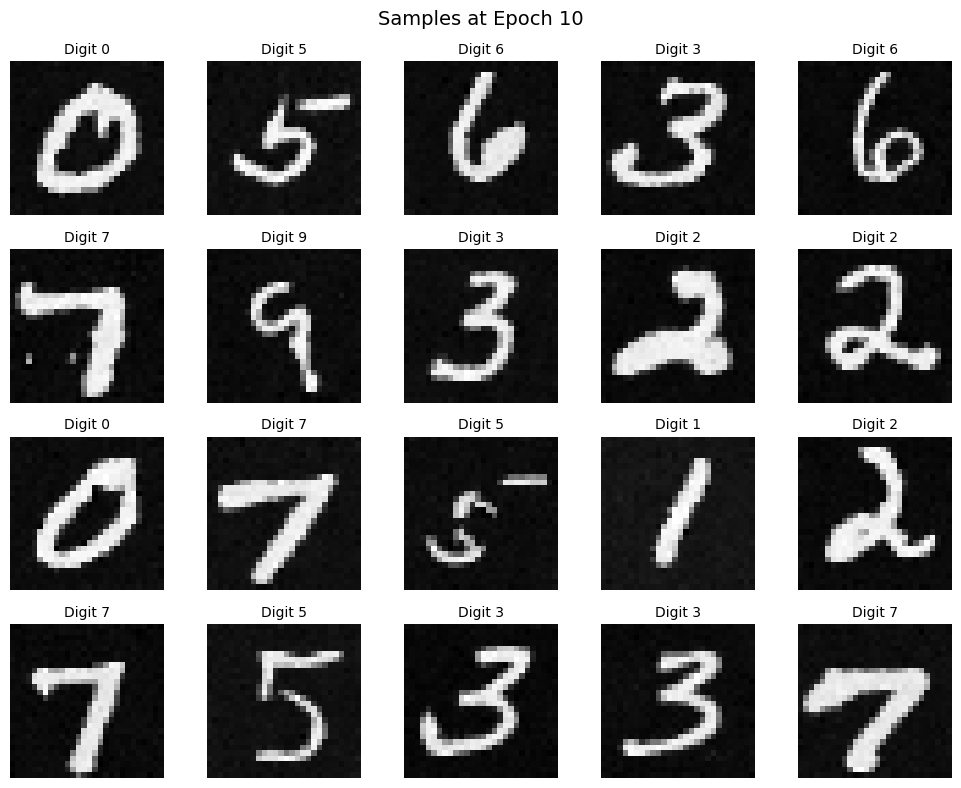

 50%|█████     | 10/20 [16:21<16:28, 98.89s/it]

Epoch [11/20], Step [0/938], Loss: 0.0323
Epoch [11/20], Step [100/938], Loss: 0.0237
Epoch [11/20], Step [200/938], Loss: 0.0338
Epoch [11/20], Step [300/938], Loss: 0.0232
Epoch [11/20], Step [400/938], Loss: 0.0240
Epoch [11/20], Step [500/938], Loss: 0.0245
Epoch [11/20], Step [600/938], Loss: 0.0353
Epoch [11/20], Step [700/938], Loss: 0.0243
Epoch [11/20], Step [800/938], Loss: 0.0350
Epoch [11/20], Step [900/938], Loss: 0.0268


 55%|█████▌    | 11/20 [17:56<14:39, 97.71s/it]

Epoch [11/20] - Average Loss: 0.0264
Epoch [12/20], Step [0/938], Loss: 0.0215
Epoch [12/20], Step [100/938], Loss: 0.0240
Epoch [12/20], Step [200/938], Loss: 0.0345
Epoch [12/20], Step [300/938], Loss: 0.0241
Epoch [12/20], Step [400/938], Loss: 0.0224
Epoch [12/20], Step [500/938], Loss: 0.0320
Epoch [12/20], Step [600/938], Loss: 0.0224
Epoch [12/20], Step [700/938], Loss: 0.0322
Epoch [12/20], Step [800/938], Loss: 0.0265
Epoch [12/20], Step [900/938], Loss: 0.0300


 60%|██████    | 12/20 [19:31<12:55, 96.88s/it]

...

 65%|██████▌   | 13/20 [21:06<11:14, 96.32s/it]

Epoch [13/20] - Average Loss: 0.0258
Epoch [14/20], Step [0/938], Loss: 0.0243
Epoch [14/20], Step [100/938], Loss: 0.0208
Epoch [14/20], Step [200/938], Loss: 0.0261
Epoch [14/20], Step [300/938], Loss: 0.0207
Epoch [14/20], Step [400/938], Loss: 0.0308
Epoch [14/20], Step [500/938], Loss: 0.0217
Epoch [14/20], Step [600/938], Loss: 0.0196
Epoch [14/20], Step [700/938], Loss: 0.0336
Epoch [14/20], Step [800/938], Loss: 0.0250
Epoch [14/20], Step [900/938], Loss: 0.0218


 70%|███████   | 14/20 [22:41<09:35, 95.94s/it]

Epoch [14/20] - Average Loss: 0.0258
Epoch [15/20], Step [0/938], Loss: 0.0221
Epoch [15/20], Step [100/938], Loss: 0.0276
Epoch [15/20], Step [200/938], Loss: 0.0220
Epoch [15/20], Step [300/938], Loss: 0.0310
Epoch [15/20], Step [400/938], Loss: 0.0252
Epoch [15/20], Step [500/938], Loss: 0.0216
Epoch [15/20], Step [600/938], Loss: 0.0295
Epoch [15/20], Step [700/938], Loss: 0.0215
Epoch [15/20], Step [800/938], Loss: 0.0265
Epoch [15/20], Step [900/938], Loss: 0.0227
Epoch [15/20] - Average Loss: 0.0255



Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.33it/s]


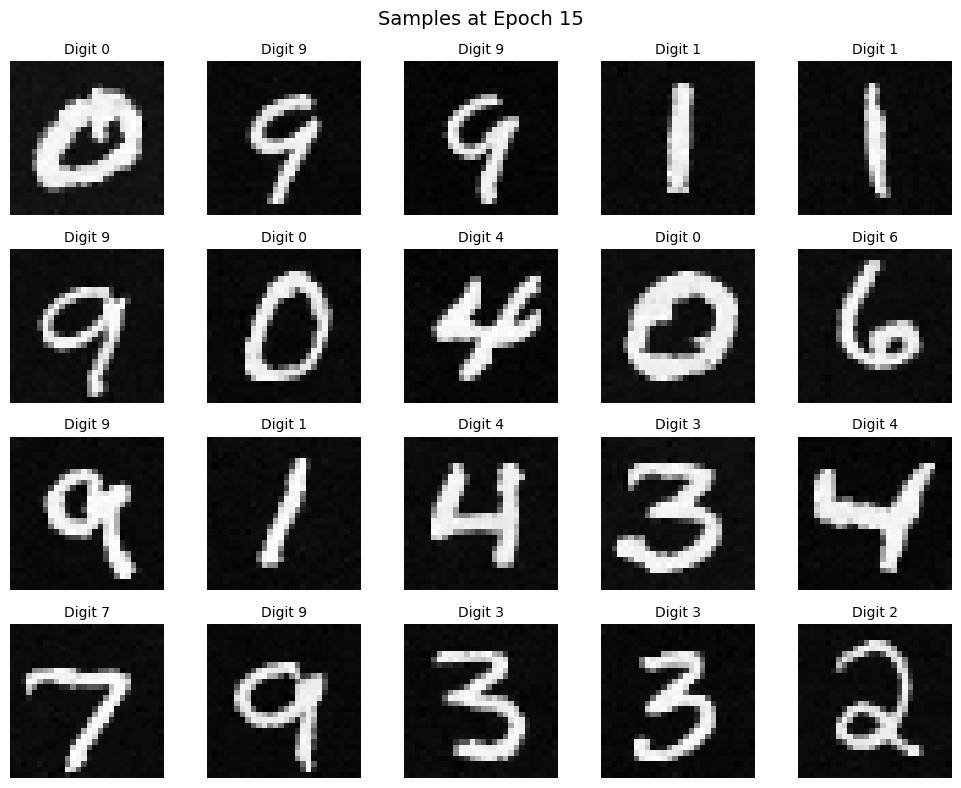

 75%|███████▌  | 15/20 [24:27<08:13, 98.80s/it]

Epoch [16/20], Step [0/938], Loss: 0.0235
Epoch [16/20], Step [100/938], Loss: 0.0217
Epoch [16/20], Step [200/938], Loss: 0.0219
Epoch [16/20], Step [300/938], Loss: 0.0233
Epoch [16/20], Step [400/938], Loss: 0.0270
Epoch [16/20], Step [500/938], Loss: 0.0241
Epoch [16/20], Step [600/938], Loss: 0.0189
Epoch [16/20], Step [700/938], Loss: 0.0269
Epoch [16/20], Step [800/938], Loss: 0.0225
Epoch [16/20], Step [900/938], Loss: 0.0299


 80%|████████  | 16/20 [26:02<06:30, 97.67s/it]

Epoch [16/20] - Average Loss: 0.0252
Epoch [17/20], Step [0/938], Loss: 0.0291
Epoch [17/20], Step [100/938], Loss: 0.0271
Epoch [17/20], Step [200/938], Loss: 0.0237
Epoch [17/20], Step [300/938], Loss: 0.0319
Epoch [17/20], Step [400/938], Loss: 0.0198
Epoch [17/20], Step [500/938], Loss: 0.0211
Epoch [17/20], Step [600/938], Loss: 0.0227
Epoch [17/20], Step [700/938], Loss: 0.0230
Epoch [17/20], Step [800/938], Loss: 0.0220
Epoch [17/20], Step [900/938], Loss: 0.0242


 85%|████████▌ | 17/20 [27:37<04:50, 96.88s/it]

...

 90%|█████████ | 18/20 [29:12<03:12, 96.33s/it]

Epoch [18/20] - Average Loss: 0.0249
Epoch [19/20], Step [0/938], Loss: 0.0282
Epoch [19/20], Step [100/938], Loss: 0.0221
Epoch [19/20], Step [200/938], Loss: 0.0233
Epoch [19/20], Step [300/938], Loss: 0.0290
Epoch [19/20], Step [400/938], Loss: 0.0220
Epoch [19/20], Step [500/938], Loss: 0.0278
Epoch [19/20], Step [600/938], Loss: 0.0193
Epoch [19/20], Step [700/938], Loss: 0.0229
Epoch [19/20], Step [800/938], Loss: 0.0233
Epoch [19/20], Step [900/938], Loss: 0.0209


 95%|█████████▌| 19/20 [30:47<01:35, 95.94s/it]

Epoch [19/20] - Average Loss: 0.0248
Epoch [20/20], Step [0/938], Loss: 0.0272
Epoch [20/20], Step [100/938], Loss: 0.0295
Epoch [20/20], Step [200/938], Loss: 0.0241
Epoch [20/20], Step [300/938], Loss: 0.0277
Epoch [20/20], Step [400/938], Loss: 0.0236
Epoch [20/20], Step [500/938], Loss: 0.0250
Epoch [20/20], Step [600/938], Loss: 0.0244
Epoch [20/20], Step [700/938], Loss: 0.0280
Epoch [20/20], Step [800/938], Loss: 0.0271
Epoch [20/20], Step [900/938], Loss: 0.0227
Epoch [20/20] - Average Loss: 0.0247



Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.35it/s]


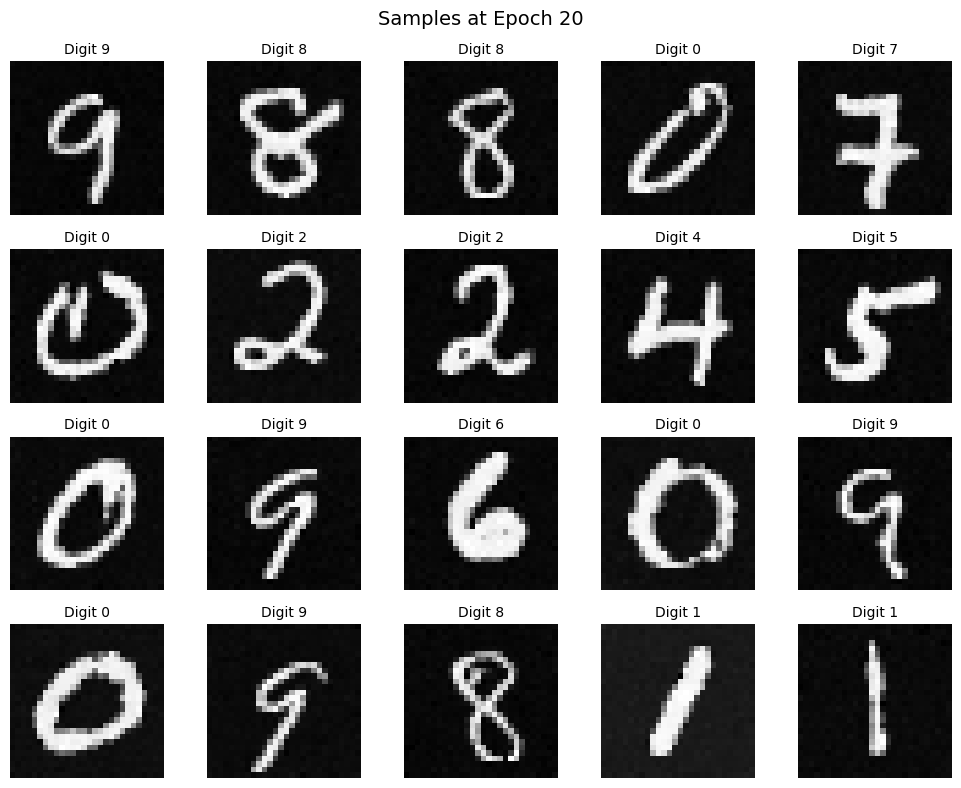

100%|██████████| 20/20 [32:32<00:00, 97.65s/it]


In [ ]:
# Hyper parameters - Modify if you wish
num_hidden = 128
batch_size = 64
num_epochs = 20
lr = 1e-3
img_wh = (28, 28)
eval_batch_size=20
T=300

# Init MNIST data loaders
train_data = MNIST(root='./data', train=True, download=True, transform=ToTensor())
test_data = MNIST(root='./data', train=False, download=True, transform=ToTensor())
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
eval_loader = DataLoader(test_data, batch_size=eval_batch_size, shuffle=True)


# Init denoiser and DDPM wrapper
denosier_unet = ConditionalDenoisingUNet(in_channels=1 , num_hiddens=num_hidden, num_classes=10)
ddpm = DDPM(denosier_unet, num_ts=T)

# Optimizer and device setup - Adam optimizer with exponential learning rate decay
optimizer = torch.optim.Adam(ddpm.parameters(), lr = lr)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optimizer, gamma = 0.1**(1.0/num_epochs))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ddpm.to(device)

# My code:
batch_losses = []
epoch_losses = []

for epoch in tqdm(range(num_epochs)):
  ddpm.train()  # Set the model to training mode
  epoch_loss = 0.0
  for batch, (data, label) in enumerate(train_loader):
      optimizer.zero_grad()
      data = data.to(device)
      label = label.to(device)
      loss = ddpm(data, label)
      loss.backward()  # Compute gradients
      optimizer.step()  # Update weights
      batch_loss = loss.item()
      batch_losses += [batch_loss]
      epoch_loss += batch_loss

      if batch % 100 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Step [{batch}/{len(train_loader)}], Loss: {batch_loss:.4f}")

  avg_epoch_loss = epoch_loss / len(train_loader)
  print(f"Epoch [{epoch+1}/{num_epochs}] - Average Loss: {avg_epoch_loss:.4f}")
  scheduler.step()


  ddpm.eval()
  epoch_losses += [avg_epoch_loss]
  if epoch in [0, 4, 9, 14, 19]:
    c = next(iter(eval_loader))[1]
    c = c.to(device)
    with torch.no_grad():
      samples = ddpm.sample(c, img_wh)  # (20, 1, H, W)
      samples = samples.cpu()
      labels = c.cpu()

      fig, axes = plt.subplots(4, 5, figsize=(10, 8))  # 4 rows × 5 columns
      axes = axes.flatten()

      for i in range(len(samples)):
          img = samples[i].squeeze(0)  # shape (H, W)
          axes[i].imshow(img, cmap='gray')
          axes[i].set_title(f"Digit {labels[i].item()}", fontsize=10)
          axes[i].axis('off')

      plt.suptitle(f"Samples at Epoch {epoch+1}", fontsize=14)
      plt.tight_layout()
      plt.show()



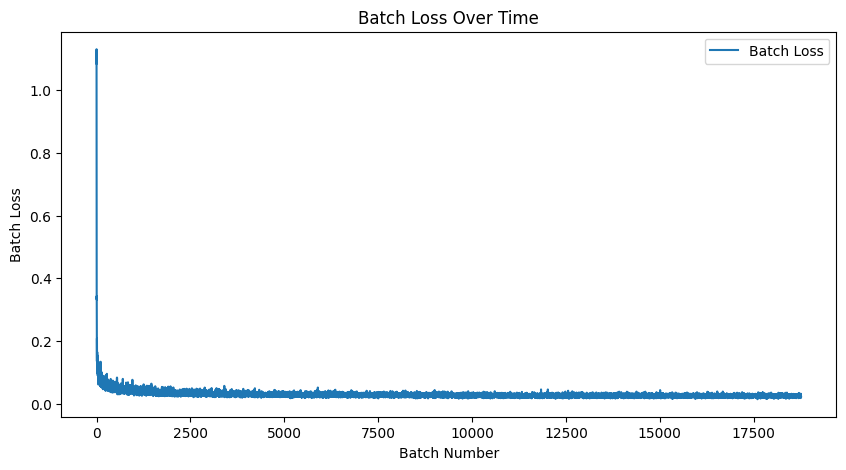

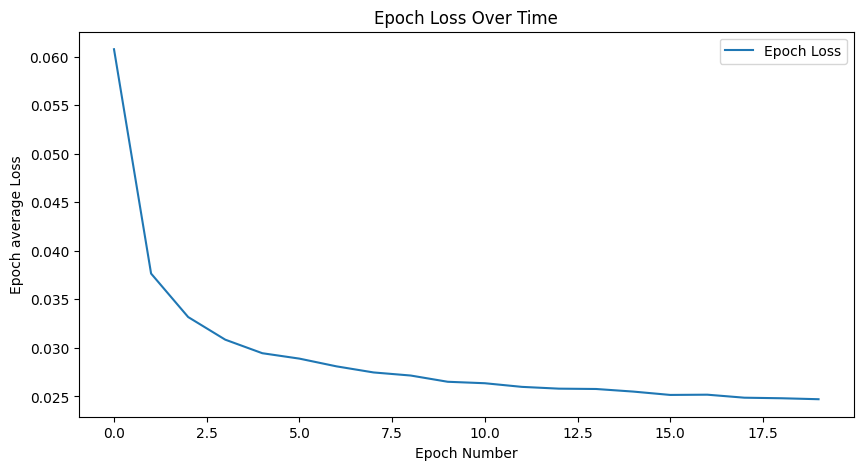

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(batch_losses, label='Batch Loss')
plt.title('Batch Loss Over Time')
plt.xlabel('Batch Number')
plt.ylabel('Batch Loss')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(epoch_losses, label='Epoch Loss')
plt.title('Epoch Loss Over Time')
plt.xlabel('Epoch Number')
plt.ylabel('Epoch average Loss')
plt.legend()
plt.show()

###3.4 Experiment with different guidance sacles


Generating images with guidance scale: 0


Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.35it/s]


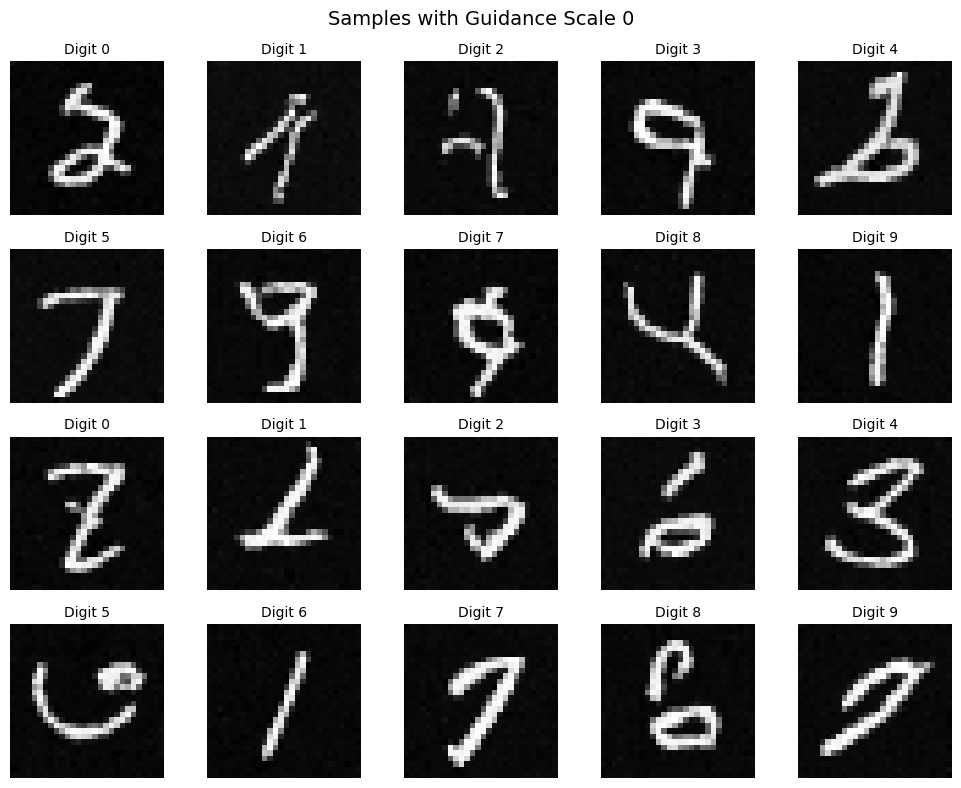


Generating images with guidance scale: 1


Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.37it/s]


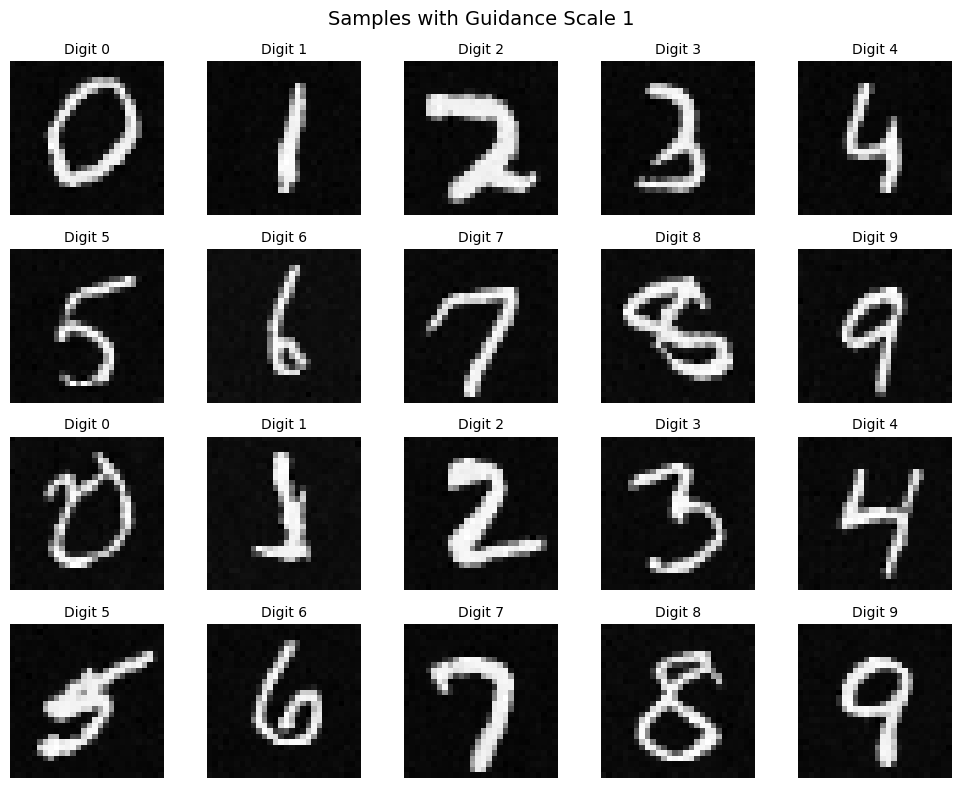


Generating images with guidance scale: 5


Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.38it/s]


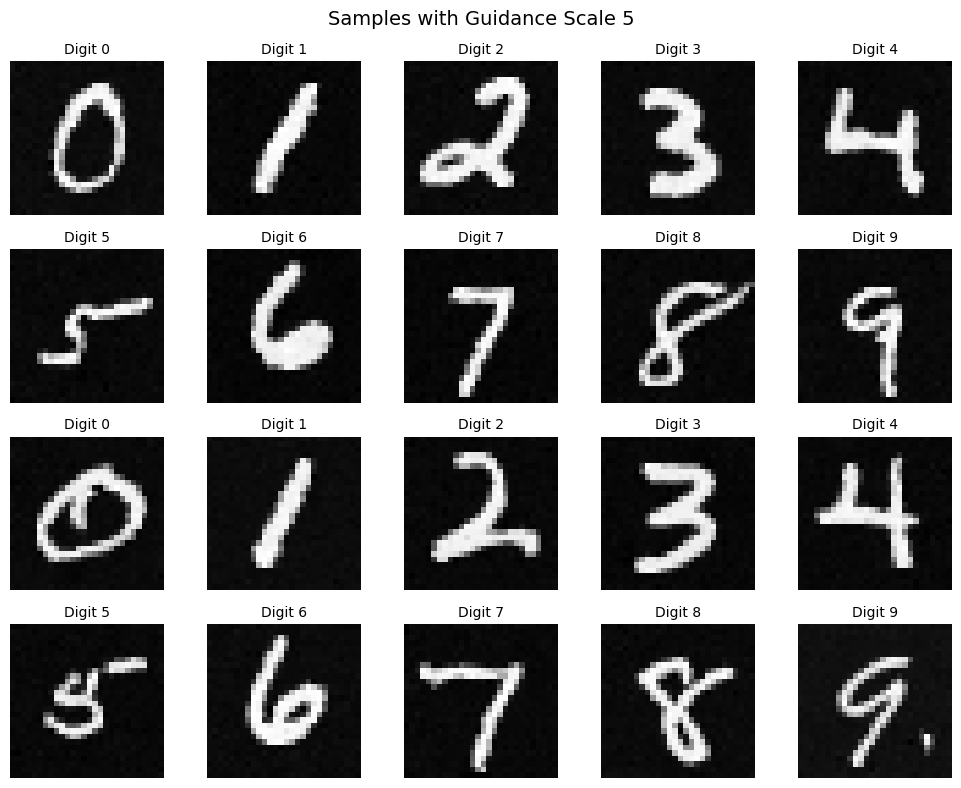


Generating images with guidance scale: 7


Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.38it/s]


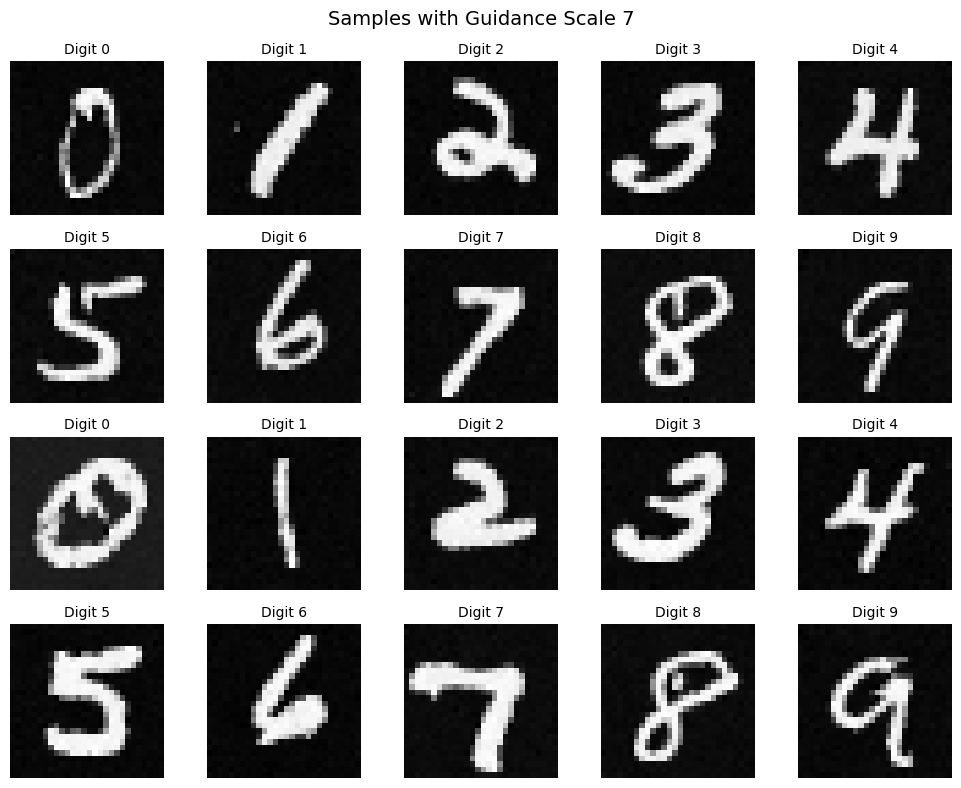


Generating images with guidance scale: 10


Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.36it/s]


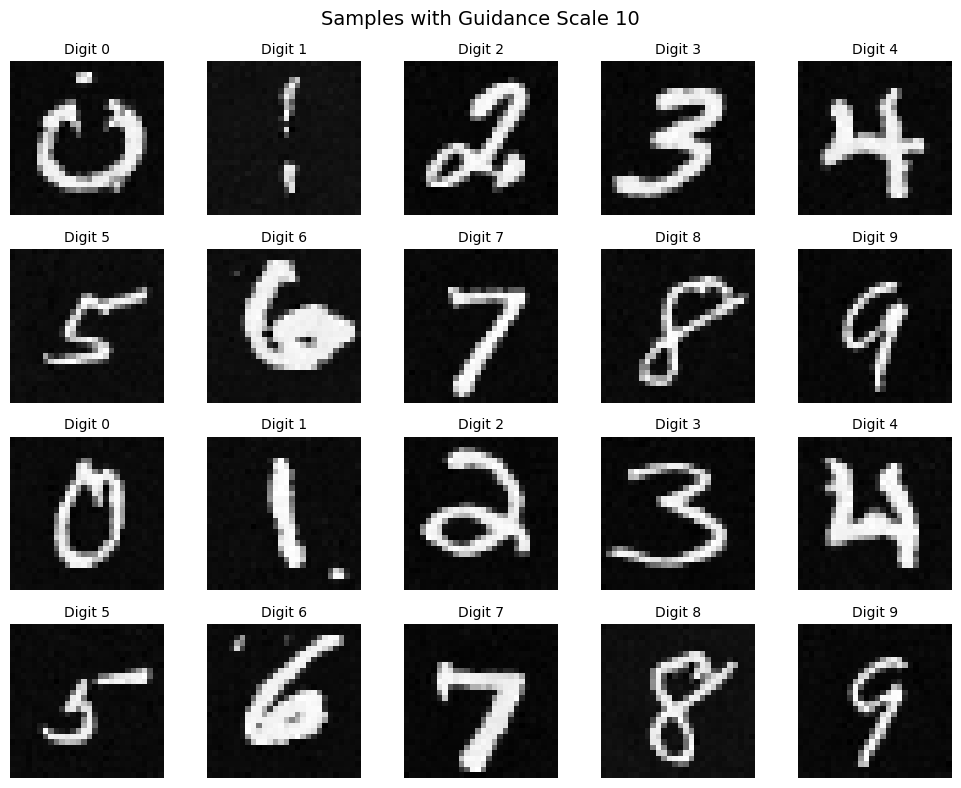


Generating images with guidance scale: 15


Sampling: 100%|██████████| 300/300 [00:09<00:00, 31.37it/s]


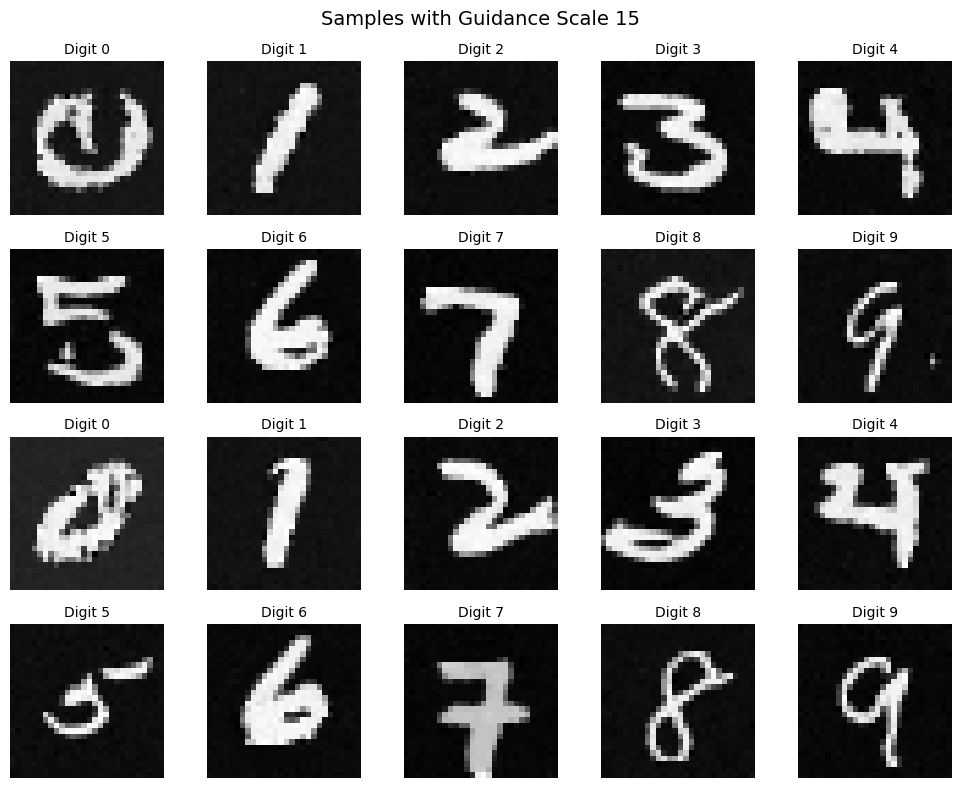

In [ ]:
guidance_scales = [0, 1, 5, 7, 10, 15]
digits_to_sample = list(range(10)) * 2  # Sample each digit twice for better visualization
c = torch.tensor(digits_to_sample, device=device)

for guidance_scale in guidance_scales:
    print(f"\nGenerating images with guidance scale: {guidance_scale}")

    with torch.no_grad():
        samples = ddpm.sample(c, img_wh, guidance_scale=guidance_scale)
        samples = samples.cpu()
        labels = c.cpu()

        fig, axes = plt.subplots(4, 5, figsize=(10, 8))  # 4 rows × 5 columns
        axes = axes.flatten()

        for i in range(len(samples)):
            img = samples[i].squeeze(0)  # shape (H, W)
            axes[i].imshow(img, cmap='gray')
            axes[i].set_title(f"Digit {labels[i].item()}", fontsize=10)
            axes[i].axis('off')

        plt.suptitle(f"Samples with Guidance Scale {guidance_scale}", fontsize=14)
        plt.tight_layout()
        plt.show()